# Fernando Dias




#📊 Análise de Dados com Python - Spotify 2019

## Autoria: Fernando Dias
## Data: Outubro de 2026


## ▶ 1. Introdução
       
####  Este notebook demostra uma estrutura padrão para iniciar uma análise de dados

TOP 50 Spotify: As 50 músicas mais ouvidas do mundo pelo Spotify.

Este conjunto de dados contém 50 músicas, 13 variáveis sobre as músicas.

Vamos explorar este dataset e responder as seguintes questões:

1.   Qual artista é mais popular?
2.   Quais são os 5 artistas mais frequenters no Top 50?
3.   Qual música tem o maior valor de danceability?
4.   Qual é a música mais longa(duration_ms) e a mais curta?
5.   Qual é a distribuição de popularidade das músicas?
6.   Qual o gênero/artista com maior energy médio?
7.   Média de batidas por minuto(tempo - BPM)?
8.   Música com positividade mais alto e mais baixo?
9.   Correlação entre energy e loudness(volume_baixo)?
10.   Contagem de gênero musicais. Quantos temos no dataset?




### 📁 2. Importação das Bibliotecas

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 📊 3. Importação dos Dados

In [3]:
df = pd.read_csv('/content/top50.csv', encoding = 'latin-1')
df

,Unnamed: 0,Track.Name,Artist.Name,Genre,Beats.Per.Minute,Energy,Danceability,Loudness..dB..,Liveness,Valence.,Length.,Acousticness..,Speechiness.,Popularity
0,1,Señorita,Shawn Mendes,canadian pop,117,55,76,-6,8,75,191,4,3,79
1,2,China,Anuel AA,reggaeton flow,105,81,79,-4,8,61,302,8,9,92
2,3,boyfriend (with Social House),Ariana Grande,dance pop,190,80,40,-4,16,70,186,12,46,85
3,4,Beautiful People (feat. Khalid),Ed Sheeran,pop,93,65,64,-8,8,55,198,12,19,86
4,5,Goodbyes (Feat. Young Thug),Post Malone,dfw rap,150,65,58,-4,11,18,175,45,7,94
5,6,I Don't Care (with Justin Bieber),Ed Sheeran,pop,102,68,80,-5,9,84,220,9,4,84
6,7,Ransom,Lil Tecca,trap music,180,64,75,-6,7,23,131,2,29,92
7,8,How Do You Sleep?,Sam Smith,pop,111,68,48,-5,8,35,202,15,9,90
8,9,Old Town Road - Remix,Lil Nas X,country rap,136,62,88,-6,11,64,157,5,10,87
9,10,bad guy,Billie Eilish,electropop,135,43,70,-11,10,56,194,33,38,95


# 🧹 4. Limpeza e Preparação dos Dados

In [4]:
# Renomeando as colunas para Português
df.rename(columns={'Track.Name': 'Música', 'Artist.Name': 'Artista', 'Genre': 'Genero',
                   'Beats.Per.Minute': 'Batidas por Minuto', 'Energy': 'Energia', 'Danceability': 'Dançabilidade',
                   'Loudness..dB..': 'Volume_DB', 'Liveness': 'Vivacidade', 'Valence.': 'Positividade', 'Length.': 'Duração',
                   'Acousticness..': 'Acústica', 'Speechiness.': 'Fala', 'Popularity': 'Popularidade'}, inplace=True)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Unnamed: 0          50 non-null     int64 
 1   Música              50 non-null     object
 2   Artista             50 non-null     object
 3   Genero              50 non-null     object
 4   Batidas por Minuto  50 non-null     int64 
 5   Energia             50 non-null     int64 
 6   Dançabilidade       50 non-null     int64 
 7   Volume_DB           50 non-null     int64 
 8   Vivacidade          50 non-null     int64 
 9   Positividade        50 non-null     int64 
 10  Duração             50 non-null     int64 
 11  Acústica            50 non-null     int64 
 12  Fala                50 non-null     int64 
 13  Popularidade        50 non-null     int64 
dtypes: int64(11), object(3)
memory usage: 5.6+ KB


# 🔍 5. Análise Exploratória

## Respondendo as questões



1.   Qual artista é mais popular?



In [6]:
df.loc[df['Popularidade'].idxmax(), ['Artista', 'Popularidade']]

,9
Artista,Billie Eilish
Popularidade,95


A artista com maior popularidade no top50 no spotify em 2019, foi Bille Eilis com índice de 95



2.   Quais são os 5 artistas mais frequentes no Top 50?



In [7]:
df['Artista'].value_counts().head(5)

,count
Artista,
Ed Sheeran,4
Shawn Mendes,2
Post Malone,2
Ariana Grande,2
Billie Eilish,2


Dentre os artistas maios frequentes estão os 5 primeiros: Ed Sheeran aparecendo 4 vezes na base de dados e os outros 4 com 2.



3.   Qual música tem o maior valor de danceability?



In [8]:
df.loc[df['Dançabilidade'].idxmax(), ['Música', 'Artista', 'Dançabilidade']]

,43
Música,Talk
Artista,Khalid
Dançabilidade,90


A música com mais dançabilidade na base de dados é do artista Khalid com a música Talk



4.   Qual é a música mais longa(duration_ms) e a mais curta?



In [9]:
# Música mais longa
df.loc[df['Duração'].idxmax(), ['Música', 'Artista', 'Duração']]

,22
Música,No Me Conoce - Remix
Artista,Jhay Cortez
Duração,309


In [10]:
# Música cmais curta
df.loc[df['Duração'].idxmin(), ['Música', 'Artista', 'Duração']]

,21
Música,Panini
Artista,Lil Nas X
Duração,115




5.   Qual é a distribuição de popularidade das músicas?



In [11]:
df['Popularidade'].describe()

,Popularidade
count,50.000000
mean,87.500000
std,4.491489
min,70.000000
25%,86.000000
50%,88.000000
75%,90.750000
max,95.000000




6.   Qual artista possui a maior energy médio?


In [12]:
df.groupby('Artista')['Energia'].mean().sort_values(ascending=False).head(5)

,Energia
Artista,
Katy Perry,88.0
Daddy Yankee,86.0
Anuel AA,81.0
Jhay Cortez,79.0
Lunay,78.0




7.   Média de batidas por minuto(tempo - BPM)?


In [13]:
df['Batidas por Minuto'].mean()

np.float64(120.06)

A média de batidas por minuto é de 120.06



8.   Música com positividade mais alto e mais baixo?



In [14]:
# Música com maior positividade
df.loc[df['Positividade'].idxmax(), ['Música', 'Artista', 'Positividade']]

,38
Música,Sucker
Artista,Jonas Brothers
Positividade,95


In [15]:
# Música com menor positividade
df.loc[df['Positividade'].idxmin(), ['Música', 'Artista', 'Positividade']]

,14
Música,Money In The Grave (Drake ft. Rick Ross)
Artista,Drake
Positividade,10


A música com maior índice de positividade (95) ficou para Jonas Brothers com Sucker e a de menor positividade (10), ficou para Drake com Money In The Grave



9.   Correlação entre energy e loudness(volume_baixo)?



In [16]:
df[['Energia', 'Volume_DB']].corr()

,Energia,Volume_DB
Energia,1.000000,0.670794
Volume_DB,0.670794,1.000000


10.   Contagem de gênero/Páis musicais. Quantos temos no dataset?




In [17]:
df.Genero.value_counts()

,count
Genero,
dance pop,8
pop,7
latin,5
canadian hip hop,3
edm,3
dfw rap,2
reggaeton flow,2
canadian pop,2
country rap,2


#📈 6. Visualização de Dados

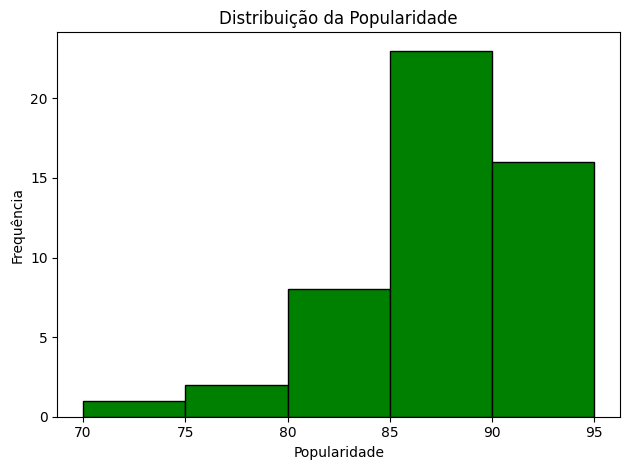

In [22]:
# Distribuição por popularidade
plt.hist(df['Popularidade'], bins=5, color='green', edgecolor='black')
plt.title('Distribuição da Popularidade')
plt.xlabel('Popularidade')
plt.ylabel('Frequência')
plt.tight_layout()
plt.show()

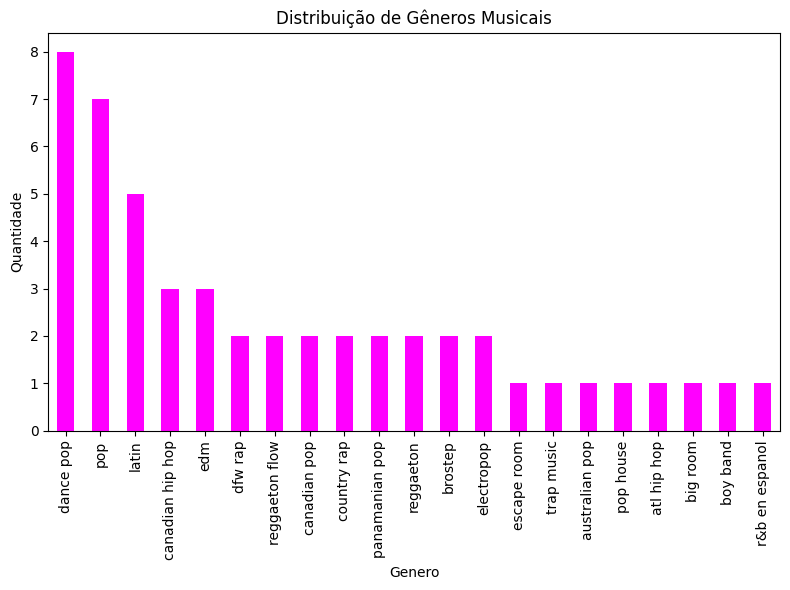

In [23]:
# Gênero musicais
df['Genero'].value_counts().plot(kind='bar', color='magenta', figsize=(8,6))
plt.title('Distribuição de Gêneros Musicais')
plt.xlabel('Genero')
plt.ylabel('Quantidade')
plt.tight_layout()
plt.show()

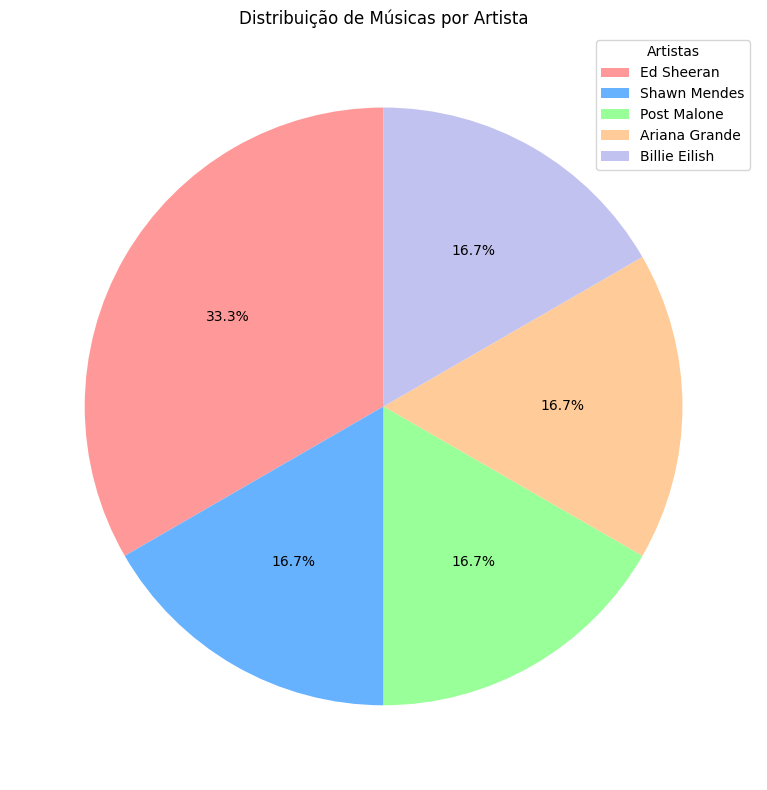

In [29]:
# Selecionando os 5 artistas mais frequentes
top_artistas = df['Artista'].value_counts().head(5)

# Definindo cores personalizadas
cores = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99', '#C2C2F0']

# Plotando gráficos de pizza
plt.figure(figsize=(10, 8))
plt.pie(top_artistas, colors=cores, autopct='%1.1f%%', startangle=90)
plt.title('Distribuição de Músicas por Artista')

# Adicionando legenda
plt.legend(top_artistas.index, title= 'Artistas', loc='best')
plt.tight_layout()
plt.show()



🧠 7. Conclusões

# Análise do dataset Spotify Top 50 - 2019
O dataset analisado contém 50 músicas maios tocadas, com informações como artista, gênero, popularidade e características musicais.
A maioria das músicas é em inglês.
Os artistas com maior frequência são grandes nomes da indústria musical, reforçando a tendência de repetição de faixas de sucesso em paradas globais.

Características musicais revelam padrãoes:


*   Top 5 dos artistas mais frequentes

*   Dançabilidade alto em músicas eletrônicas e pop.

*   Energia e volume baixo estão fortemente correlacionandos (0.67), indicando que músicas mais energéticas tendem a ser mais "altas".

*   O tempo médio gira em torno de 120 BPM, típico de músicas de dança-pop.

*   Análises de positividade (valence) destacam músicas alegres e outras com tom mais melancólico, evidenciando variedade de estilos.



